# Эксперимент 1. Одно событие на заключение

Вариант «категории × 2», поиск способов поднять precision моделей.

**Идея.** В основном варианте заключение с несколькими категориями даёт цепочку событий (по тяжести, время 0).
Майнеры видят в этих цепочках параллельность и циклы и строят модель, которая разрешает много лишних путей.
Здесь от каждого заключения остаётся **одна категория — самая тяжёлая** (при равной тяжести — случайная, seed 42;
`Justice` — только если в заключении нет других категорий). Трасса человека становится простой
последовательностью заключений.

**Зачем.** Проверить, насколько низкая precision вызвана развилками внутри заключения. В Этапе 1 вариант
«одна категория на эпизод» давал precision около 0.87 против 0.65–0.75 с развилками.

**Цена.** Теряются менее тяжёлые категории заключения (в основном варианте 8 484 шага из 21 866 с развилкой).

**Как запустить.** Окружение `D:\Git\diploma\.venv`, открыть ноутбук из этой папки, *Run All*. Вход — таблица этапа 0
(`jupyter lab\stage0 - data\out\compas_custody_charges.csv`), общий код журнала — `x2_common.py` рядом (тот же, что в
`oldcase_x2`). Результаты пишутся в `out\` этой папки.

**Как сравниваются модели.** Как в `oldcase_x2`: люди делятся на train 80% / test 20% (seed 42), модели строятся на
train, fitness и precision считаются token-based replay на первых 2 000 людях train и test. Базовая линия — вариант
`oldcase_x2` (29 состояний, порядок по тяжести): HM 0.9 — fitness 0.982, precision 0.543; IM 0.2 — 0.994 / 0.383.

## Шаг 0. Настройки

In [1]:
import os, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

warnings.filterwarnings("ignore")
os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "False"
for gv in [Path(r"D:\Graphviz\bin")]:
    if gv.exists() and str(gv) not in os.environ["PATH"]:
        os.environ["PATH"] = str(gv) + os.pathsep + os.environ["PATH"]
import pm4py
import x2_common as X

HERE = Path.cwd()
ROOT = HERE.parent.parent                       # jupyter lab (на компьютере) или корень репозитория
CANDIDATES = [ROOT / "stage0 - data" / "out" / "compas_custody_charges.csv",
              ROOT / "stage0-data" / "compas_custody_charges.csv"]
DATA = next((p for p in CANDIDATES if p.exists()), CANDIDATES[0])
OUT = HERE / "out"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

EXP = "x2_exp1_one_event"
BUILD = {'one_event': True}       # параметры журнала
MERGE_RARE = False      # слить редкие OldCase: X
MIN_EVENTS = 300            # порог «редкого» состояния
MODELS = ['HM_0.5', 'HM_0.9', 'HM_0.95', 'IM_0.2', 'IM_0.5']
EVAL_CASES = 2000           # людей в выборках train/test для fitness/precision
RUN_ILP = False             # ILP Miner (долго)
ALIGN_CASES = 2000          # precision через выравнивания для HM 0.9 на стольких людях из test (0 — не считать);
                            # чем меньше выборка, тем ниже precision (часть префиксов не встречается), поэтому 2000
print("pm4py", pm4py.__version__, "| вход:", DATA, DATA.exists())


def show(path, max_px=1400):
    from io import BytesIO
    from PIL import Image as PILImage
    PILImage.MAX_IMAGE_PIXELS = None
    im = PILImage.open(path)
    im.thumbnail((max_px, max_px))
    buf = BytesIO()
    im.convert("RGB").save(buf, format="JPEG", quality=80)
    display(Image(data=buf.getvalue(), format="jpeg"))



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.9 | вход: /tmp/claude-0/w/exproot/stage0 - data/out/compas_custody_charges.csv True


## Шаг 1. Журнал событий

In [2]:
ch, ep = X.load(DATA)
merge_old = ()
if MERGE_RARE:
    base_ev, _, _ = X.build("x2", ch, ep, **{k: v for k, v in BUILD.items() if k != "merge_old"})
    vc = base_ev["concept:name"].value_counts()
    merge_old = sorted(a for a, n in vc.items() if a.startswith(X.OLD_PREFIX) and n < MIN_EVENTS)
    print("сливаются в «OldCase: Other»:", ", ".join(f"{a} ({vc[a]})" for a in merge_old))
ev, st, info = X.build("x2", ch, ep, merge_old=merge_old, **BUILD)
info

{'variant': 'x2',
 'people': 10580,
 'episodes': 21716,
 'justice_steps': 0,
 'steps': 21716,
 'events': 21716,
 'transitions': 11136,
 'people_repeat': 5209,
 'multi_type_steps': 0,
 'activities': 28,
 'obs_end': '2016-04-19'}

In [3]:
log = pm4py.format_dataframe(ev[["case:concept:name", "concept:name", "time:timestamp"]].copy(),
                             case_id="case:concept:name", activity_key="concept:name", timestamp_key="time:timestamp")
dfg, sa, ea = pm4py.discover_dfg(log)
traces = st.groupby("id")["state"].agg(" → ".join).value_counts()
stats = pd.Series({"состояний": log["concept:name"].nunique(), "событий": len(log), "шагов": len(st),
                   "дуг DFG": len(dfg), "петель DFG (X→X)": sum(a == b for a, b in dfg),
                   "вариантов трасс": len(traces), "людей с уникальной трассой": int((traces == 1).sum())})
ev.to_csv(OUT / f"event_log_{EXP}.csv", index=False)
stats.to_csv(OUT / "log_stats.csv", header=["value"])
print(log["concept:name"].value_counts().to_string())
stats

concept:name
Violent                  4599
Property                 3690
Drug                     3359
Traffic                  2238
OldCase: Property        1601
OldCase: Drug            1534
OldCase: Violent          862
Unknown                   653
Fraud                     530
OldCase: Traffic          506
ResistPolice              503
PublicOrder               285
Tampering                 246
Weapon                    238
Sex                       229
OldCase: Fraud            197
OldCase: ResistPolice     122
OldCase: Weapon           105
OldCase: Sex               67
OldCase: Tampering         64
OldCase: PublicOrder       26
Justice                    22
Conspiracy                 19
OldCase: Conspiracy         8
Minors                      7
OldCase: Justice            4
OldCase: Minors             1
Other                       1


состояний                        28
событий                       21716
шагов                         21716
дуг DFG                         368
петель DFG (X→X)                 24
вариантов трасс                1729
людей с уникальной трассой     1321
dtype: int64

## Шаг 2. Граф: DFG (30% путей) и сеть Петри Heuristics Miner 0.9

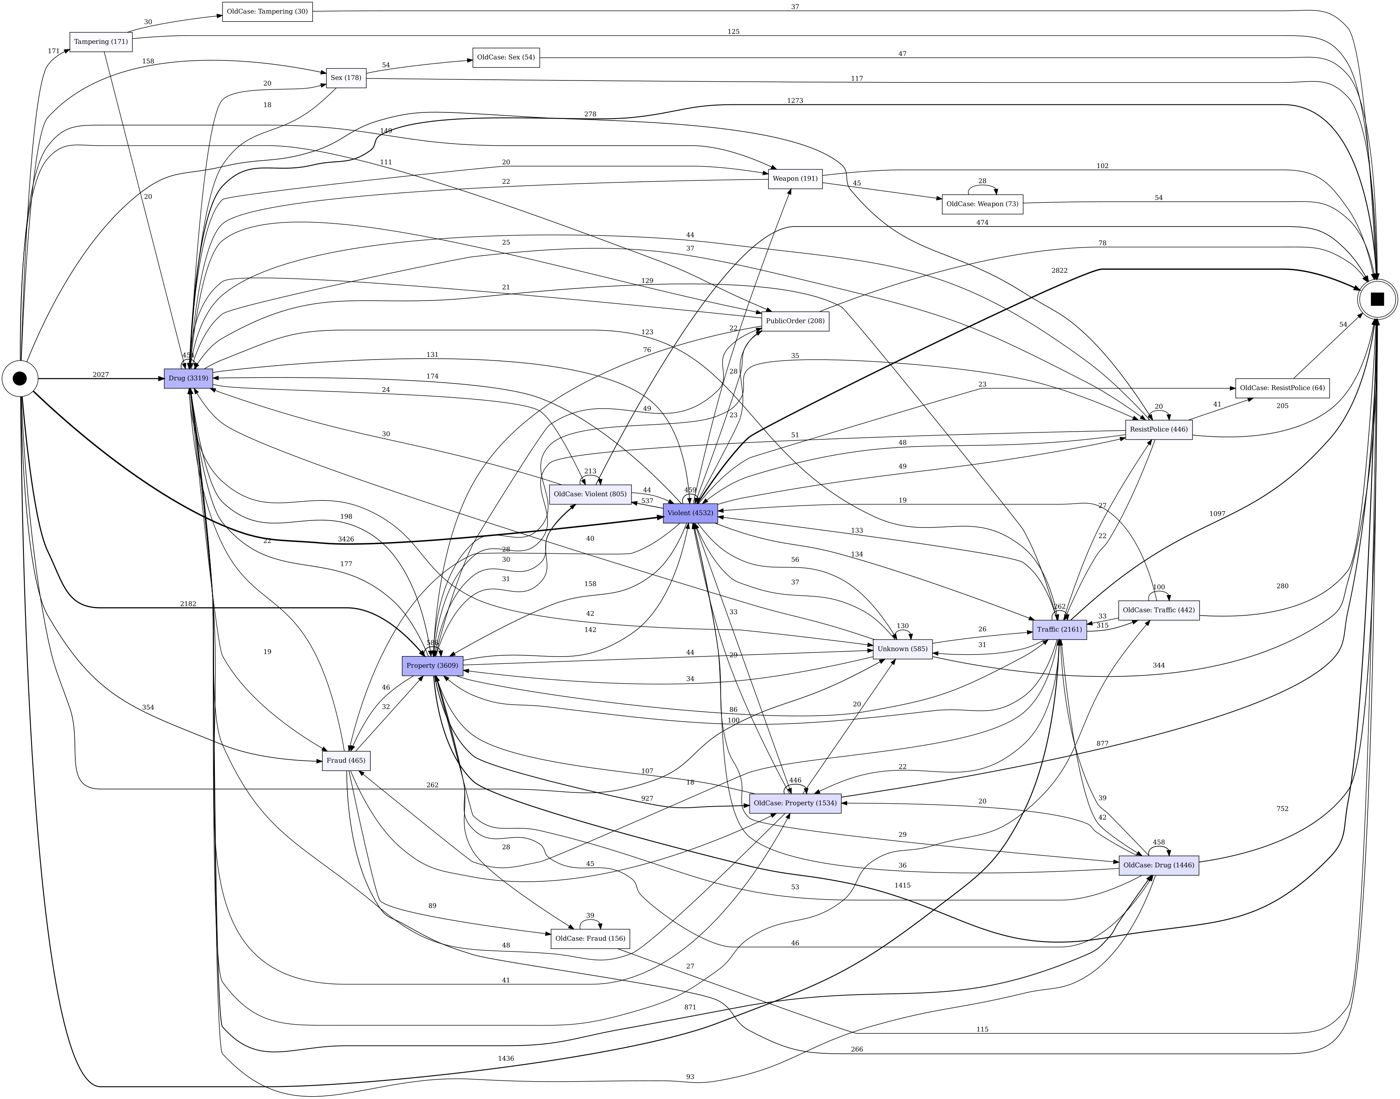

In [4]:
dfg_f, sa_f, ea_f = pm4py.filter_dfg_paths_percentage(dfg, sa, ea, 0.3)
# у pm4py 2.7.23.9 рисунок падает, если начальная/конечная активность не осталась ни на одной дуге — убираем такие
acts_f = {a for k in dfg_f for a in k}
sa_f = {a: n for a, n in sa_f.items() if a in acts_f}
ea_f = {a: n for a, n in ea_f.items() if a in acts_f}
pm4py.save_vis_dfg(dfg_f, sa_f, ea_f, str(FIG / "dfg_frequency_paths30.png"))
show(FIG / "dfg_frequency_paths30.png")

HM 0.9 на всём журнале: мест 50, переходов 211


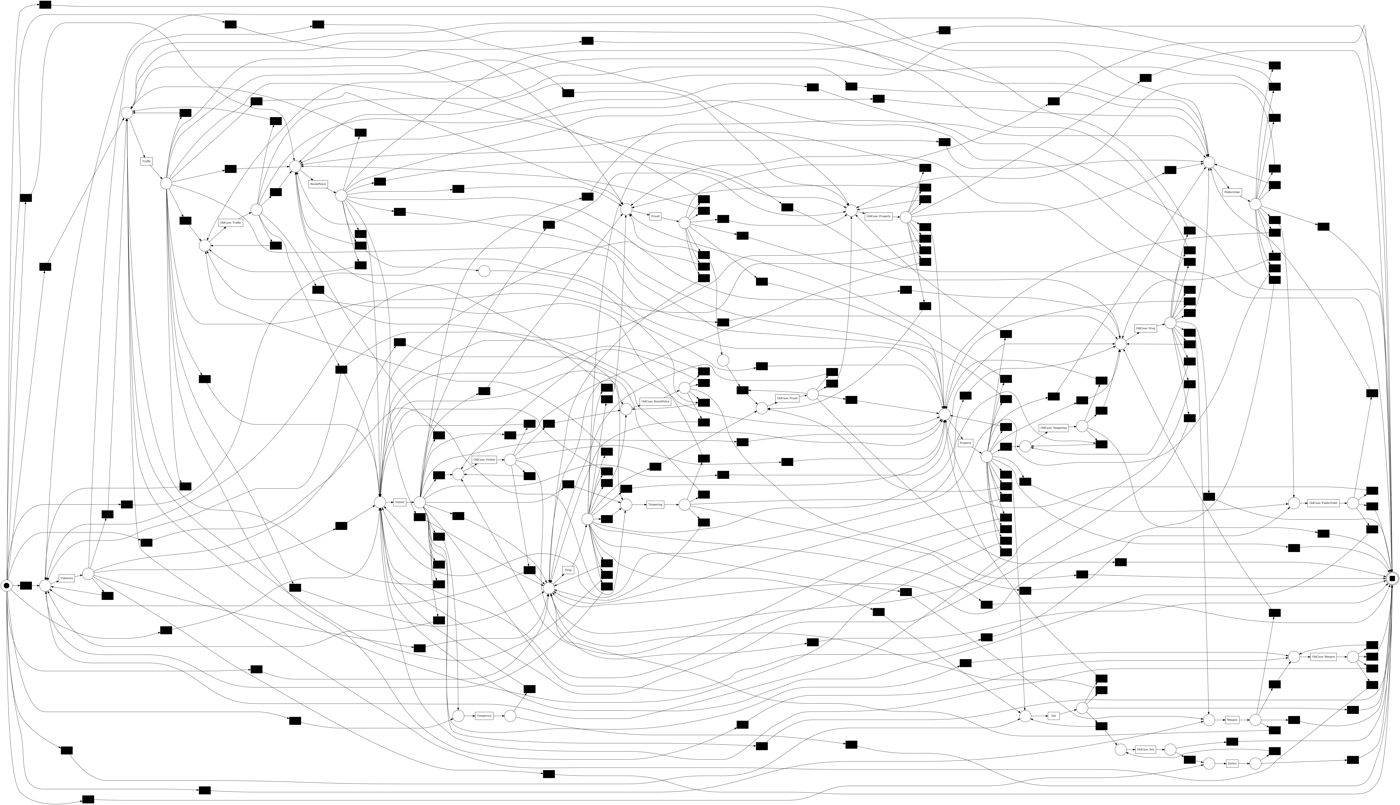

In [5]:
net, im, fm = pm4py.discover_petri_net_heuristics(log, dependency_threshold=0.9)
pm4py.save_vis_petri_net(net, im, fm, str(FIG / "petri_HM_dep0.9.png"))
print(f"HM 0.9 на всём журнале: мест {len(net.places)}, переходов {len(net.transitions)}")
show(FIG / "petri_HM_dep0.9.png")

## Шаг 3. Модели и качество

Названия моделей: `HM_d` — Heuristics Miner с порогом зависимости d; `HM_0.9_min30` — то же, дуги реже 30 раз
отбрасываются; `HM_0.9_and0.95` — то же, параллельность (AND) объявляется только при мере ≥ 0.95; `IM_n` — Inductive Miner с порогом шума n; `*_freq` — модель построена только по людям с
трассой, которая встречается хотя бы у двух человек (проверка — на всех); `ILP` — ILP Miner.

In [6]:
train, test = X.split_people(log)
train_s, test_s = X.sample_cases(train, EVAL_CASES), X.sample_cases(test, EVAL_CASES)


def frequent_train():
    # люди из train, чья трасса (последовательность событий) встречается хотя бы у двух человек
    seq = train.groupby("case:concept:name")["concept:name"].agg(tuple)
    n = seq.map(seq.value_counts())
    return train[train["case:concept:name"].isin(n[n >= 2].index)]


def discover(name):
    if name.startswith("HM_"):
        parts = name.split("_")
        lg = frequent_train() if name.endswith("_freq") else train
        kw = dict(dependency_threshold=float(parts[1]))
        if "min30" in name:
            kw["min_dfg_occurrences"] = 30
        return pm4py.discover_petri_net_heuristics(lg, **kw)
    if name.startswith("IM_"):
        lg = frequent_train() if name.endswith("_freq") else train
        return pm4py.discover_petri_net_inductive(lg, noise_threshold=float(name.split("_")[1]))
    if name == "ILP":
        return pm4py.discover_petri_net_ilp(train)
    raise ValueError(name)


models, times = {}, {}
for name in MODELS:
    if name == "ILP" and not RUN_ILP:
        continue
    t0 = time.time()
    models[name] = discover(name)
    times[name] = round(time.time() - t0)
    print(f"{name}: построена за {times[name]} с")

HM_0.5: построена за 0 с
HM_0.9: построена за 0 с


HM_0.95: построена за 0 с


IM_0.2: построена за 0 с
IM_0.5: построена за 0 с


In [7]:
quality = X.evaluate(models, train_s, test_s)
quality["discover_sec"] = quality["model"].map(times)
if ALIGN_CASES and "HM_0.9" in models:
    t0 = time.time()
    pa = pm4py.precision_alignments(X.sample_cases(test, ALIGN_CASES), *models["HM_0.9"])
    quality.loc[(quality["model"] == "HM_0.9") & (quality["split"] == "test"), "precision_align"] = round(pa, 4)
    print(f"HM 0.9: precision через выравнивания на {ALIGN_CASES} людях = {pa:.4f} ({time.time() - t0:.0f} с)")
quality.to_csv(OUT / "model_quality.csv", index=False)
quality[quality["split"] == "test"]

{'model': 'HM_0.5', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9209, 'pct_fit_traces': 66.15, 'precision_tbr': 0.7608, 'f1': 0.8332, 'places': 79, 'transitions': 251, 'silent': 224, 'sec': 2}


{'model': 'HM_0.5', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9187, 'pct_fit_traces': 63.95, 'precision_tbr': 0.8209, 'f1': 0.867, 'places': 79, 'transitions': 251, 'silent': 224, 'sec': 2}


{'model': 'HM_0.9', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9822, 'pct_fit_traces': 89.8, 'precision_tbr': 0.7333, 'f1': 0.8397, 'places': 48, 'transitions': 198, 'silent': 175, 'sec': 2}


{'model': 'HM_0.9', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9831, 'pct_fit_traces': 90.15, 'precision_tbr': 0.796, 'f1': 0.8797, 'places': 48, 'transitions': 198, 'silent': 175, 'sec': 2}


{'model': 'HM_0.95', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9833, 'pct_fit_traces': 91.0, 'precision_tbr': 0.7354, 'f1': 0.8415, 'places': 48, 'transitions': 196, 'silent': 173, 'sec': 2}


...

{'model': 'IM_0.2', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9757, 'pct_fit_traces': 79.6, 'precision_tbr': 0.5286, 'f1': 0.6857, 'places': 81, 'transitions': 126, 'silent': 99, 'sec': 2}


{'model': 'IM_0.5', 'split': 'train', 'cases': 2000, 'fitness_tbr': 0.9335, 'pct_fit_traces': 67.6, 'precision_tbr': 0.4782, 'f1': 0.6324, 'places': 58, 'transitions': 102, 'silent': 75, 'sec': 1}


{'model': 'IM_0.5', 'split': 'test', 'cases': 2000, 'fitness_tbr': 0.9333, 'pct_fit_traces': 66.95, 'precision_tbr': 0.5512, 'f1': 0.6931, 'places': 58, 'transitions': 102, 'silent': 75, 'sec': 1}


HM 0.9: precision через выравнивания на 2000 людях = 0.7963 (4 с)


,model,split,cases,fitness_tbr,pct_fit_traces,precision_tbr,f1,places,transitions,silent,sec,discover_sec,precision_align
1,HM_0.5,test,2000,0.9187,63.95,0.8209,0.8670,79,251,224,2,0,NaN
3,HM_0.9,test,2000,0.9831,90.15,0.7960,0.8797,48,198,175,2,0,0.7963
5,HM_0.95,test,2000,0.9841,91.40,0.7960,0.8801,48,196,173,2,0,NaN
7,IM_0.2,test,2000,0.9757,79.60,0.5286,0.6857,81,126,99,2,0,NaN
9,IM_0.5,test,2000,0.9333,66.95,0.5512,0.6931,58,102,75,1,0,NaN


## Шаг 4. Сравнение с основным вариантом oldcase_x2

In [8]:
BASE = pd.DataFrame({"model": ["HM_0.5", "HM_0.9", "IM_0.0", "IM_0.2", "IM_0.5"],
                     "fitness_base": [0.9415, 0.9821, 1.0, 0.9938, 0.9716],
                     "precision_base": [0.6136, 0.5430, 0.3688, 0.3828, 0.4563]})
cmp = quality[quality["split"] == "test"][["model", "fitness_tbr", "precision_tbr", "f1"]].merge(BASE, on="model", how="left")
cmp["Δ precision"] = (cmp["precision_tbr"] - cmp["precision_base"]).round(4)
cmp.to_csv(OUT / "compare_with_oldcase_x2.csv", index=False)
cmp

,model,fitness_tbr,precision_tbr,f1,fitness_base,precision_base,Δ precision
0,HM_0.5,0.9187,0.8209,0.8670,0.9415,0.6136,0.2073
1,HM_0.9,0.9831,0.7960,0.8797,0.9821,0.5430,0.2530
2,HM_0.95,0.9841,0.7960,0.8801,NaN,NaN,NaN
3,IM_0.2,0.9757,0.5286,0.6857,0.9938,0.3828,0.1458
4,IM_0.5,0.9333,0.5512,0.6931,0.9716,0.4563,0.0949
